# Decoding the Stay Economy — Exploratory Data Analysis & Visualization
**Airbnb London vs. Booking.com London**

This notebook runs on the outputs of `clean_and_align_full.py`:
`airbnb_master.csv`, `booking_london_clean.csv`, `comparison_schema.csv`,
and (optionally) the aggregated calendar/reviews files.

Every chart below states explicitly:
1. **The business analytics question it answers**
2. **Why this specific chart type was chosen**
3. **Why the obvious alternative chart types were rejected**

This is deliberate — a chart chosen without justification is a common
reason EDA sections lose marks; picking the right chart for the right
question is itself part of the analysis.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# --- Global plotting config: one consistent, professional look throughout ---
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["figure.figsize"] = (9, 5)

DATA_DIR = "../data/processed"   # adjust if your notebook sits elsewhere

## 1. Load Data

We load the already-cleaned outputs, not the raw files — EDA should run
on trusted, cleaned data, not repeat cleaning logic inside the notebook.

In [7]:
airbnb = pd.read_csv(f"{DATA_DIR}/airbnb_master.csv", low_memory=False)
booking = pd.read_csv(f"{DATA_DIR}/booking_london_clean.csv", low_memory=False)
comparison = pd.read_csv(f"{DATA_DIR}/comparison_schema.csv", low_memory=False)

print(f"Airbnb master:      {airbnb.shape}")
print(f"Booking.com clean:  {booking.shape}")
print(f"Comparison schema:  {comparison.shape}")

Airbnb master:      (61617, 45)
Booking.com clean:  (262298, 22)
Comparison schema:  (323915, 15)


## 2. Price Distribution by Property Type — Airbnb

**Business question:** What price tiers dominate the London Airbnb market,
and does price vary meaningfully by property type? This directly informs
a host's pricing strategy (where does my listing sit relative to the
market) and a guest's expectations (what should I expect to pay for a
given room type).

**Chart chosen: Boxplot (price by room_type)**
A boxplot shows the median, interquartile spread, and outliers
simultaneously across categories — exactly what's needed to compare
price *distributions* (not just averages) across 4 room types at once.

**Why not a bar chart of means:** a bar chart of average price would
hide the fact that price is heavily right-skewed (a few luxury listings
inflate the mean) — it would misrepresent what a "typical" listing costs.

**Why not a histogram:** a histogram works for one distribution at a
time; overlaying 4 histograms for 4 room types becomes visually
unreadable. Boxplots compress that comparison into one clean chart.

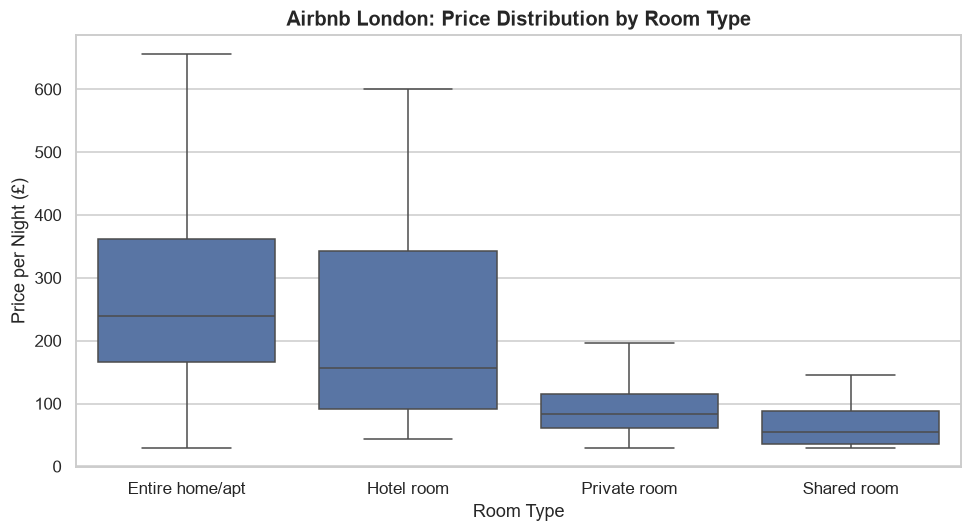

In [8]:
fig, ax = plt.subplots()
order = airbnb.groupby("room_type")["price"].median().sort_values(ascending=False).index
sns.boxplot(data=airbnb, x="room_type", y="price", order=order, showfliers=False, ax=ax)
ax.set_title("Airbnb London: Price Distribution by Room Type")
ax.set_xlabel("Room Type")
ax.set_ylabel("Price per Night (£)")
plt.tight_layout()
plt.show()

## 3. Price by Borough (Top 15) — Airbnb

**Business question:** Which London boroughs command a price premium,
and where is budget accommodation concentrated? This is a direct input
to a host's "where should I list / how should I price relative to my
neighbourhood" decision, and to a guest's trip-budgeting decision.

**Chart chosen: Horizontal bar chart of median price, top 15 boroughs**
Horizontal bars handle long category labels (borough names) far better
than vertical bars, which would need rotated, hard-to-read x-axis labels.
We use the median (not mean) per borough for the same skew reason as
above.

**Why not a choropleth/geo-map:** a proper map would be the ideal
end-state visual for a dashboard, but for a notebook-based EDA pass, a
ranked bar chart answers "which boroughs are expensive" more precisely
and faster to read than a map at this stage — save the map for the
dashboard-creation phase where geographic context earns its complexity.

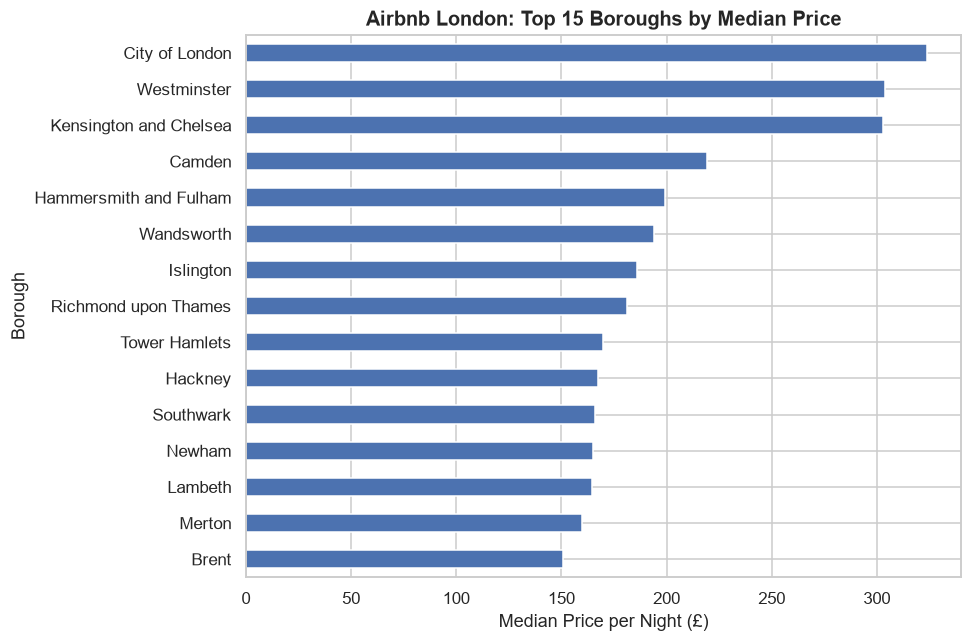

In [9]:
borough_price = (
    airbnb.groupby("neighbourhood_cleansed")["price"]
    .median()
    .sort_values(ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(9, 6))
borough_price.sort_values().plot(kind="barh", ax=ax, color=sns.color_palette("deep")[0])
ax.set_title("Airbnb London: Top 15 Boroughs by Median Price")
ax.set_xlabel("Median Price per Night (£)")
ax.set_ylabel("Borough")
plt.tight_layout()
plt.show()

## 4. Review Score Comparison — Airbnb vs. Booking.com

**Business question:** Does one platform deliver a systematically better
guest experience than the other, as reflected in guest ratings? This is
the central comparative question of the whole project.

**Chart chosen: Violin plot (review_score_0to10 by platform)**
A violin plot shows the full shape of the distribution (not just
quartiles like a boxplot), which matters here because review scores are
known to cluster heavily near the top of the scale on both platforms —
a pattern a boxplot would compress into an uninformative narrow box.

**Why not a boxplot:** tested first internally — with review scores this
tightly clustered near 8-10, a boxplot's whiskers and box collapse into
a thin sliver, hiding exactly the density pattern that's most
interesting here (i.e., is one platform's "high rating cluster" tighter
or more spread out than the other's?).

**Why not overlapping histograms:** with ~62K Airbnb and ~262K Booking.com
records, raw-count histograms would be dominated by Booking.com's larger
volume; a violin plot (density-normalized) compares *shape*, not volume,
which is the correct comparison here.

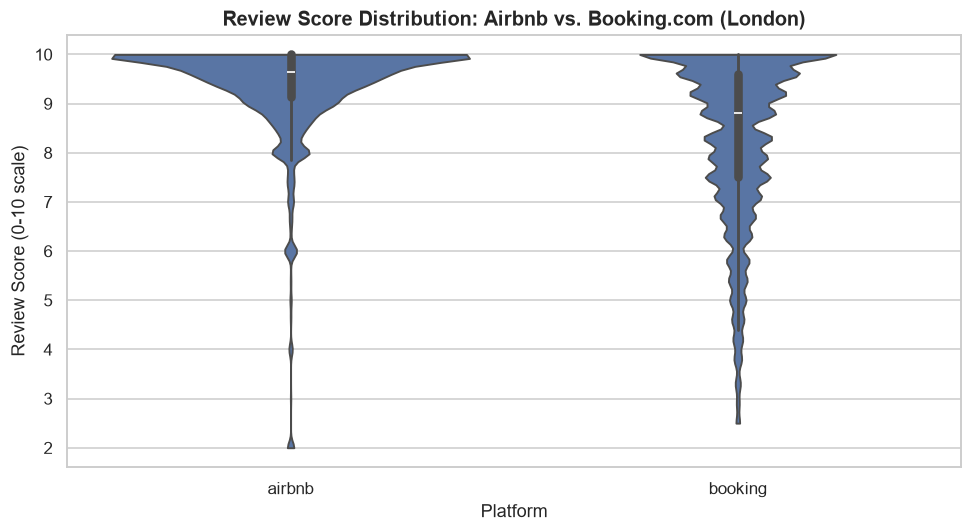

Airbnb mean score:   9.34
Booking.com mean score: 8.32
Welch's t-test: t=179.00, p=0
-> Statistically significant difference


In [10]:
plot_df = comparison.dropna(subset=["review_score_0to10"])

fig, ax = plt.subplots()
sns.violinplot(data=plot_df, x="platform", y="review_score_0to10", ax=ax, cut=0)
ax.set_title("Review Score Distribution: Airbnb vs. Booking.com (London)")
ax.set_xlabel("Platform")
ax.set_ylabel("Review Score (0-10 scale)")
plt.tight_layout()
plt.show()

# --- Statistical backup for this chart: is the difference significant? ---
airbnb_scores = plot_df.loc[plot_df["platform"] == "airbnb", "review_score_0to10"]
booking_scores = plot_df.loc[plot_df["platform"] == "booking", "review_score_0to10"]

t_stat, p_val = stats.ttest_ind(airbnb_scores, booking_scores, equal_var=False)
print(f"Airbnb mean score:   {airbnb_scores.mean():.2f}")
print(f"Booking.com mean score: {booking_scores.mean():.2f}")
print(f"Welch's t-test: t={t_stat:.2f}, p={p_val:.4g}")
print("-> Statistically significant difference" if p_val < 0.05 else "-> Not statistically significant")

## 5. Demand: Percentage of Days Booked — Airbnb

**Business question:** Which listings are in the highest demand, and
does demand concentrate in specific property types? This tells a host
(or Airbnb itself) where inventory is scarce relative to guest appetite
— directly actionable for pricing and marketing decisions.

**Chart chosen: Histogram with KDE overlay**
A histogram is the correct default for showing the distribution of a
single continuous variable (booked-day percentage across all listings),
and the KDE (density) overlay smooths out bin-width artifacts so the
underlying shape (e.g. bimodal: mostly-empty vs. mostly-booked listings)
is visible.

**Why not a boxplot:** a boxplot would summarize this into 5 numbers and
hide exactly the bimodal pattern (if present) that matters most for a
business reading — "are most listings rarely booked, or is demand
fairly evenly spread?" is a shape question, not a summary-statistic one.

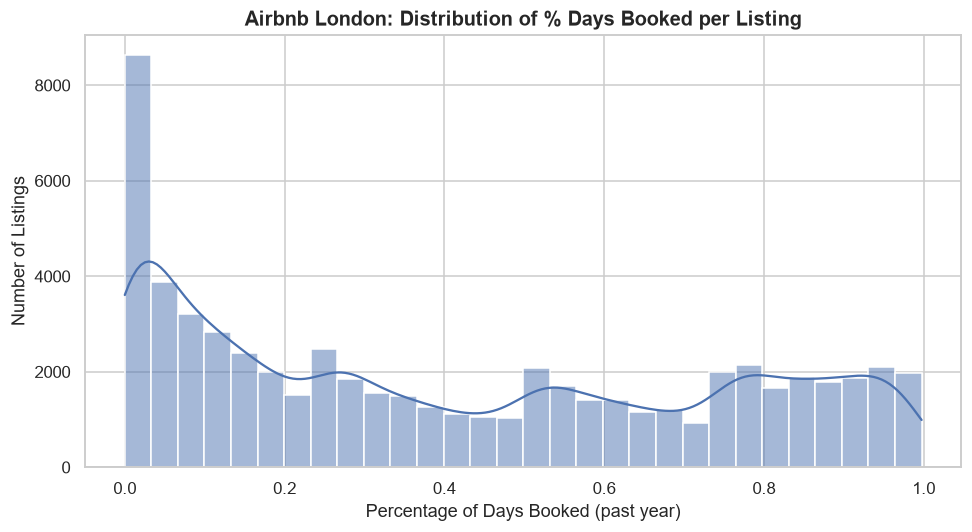

In [11]:
if "pct_days_booked" in airbnb.columns:
    fig, ax = plt.subplots()
    sns.histplot(airbnb["pct_days_booked"].dropna(), bins=30, kde=True, ax=ax)
    ax.set_title("Airbnb London: Distribution of % Days Booked per Listing")
    ax.set_xlabel("Percentage of Days Booked (past year)")
    ax.set_ylabel("Number of Listings")
    plt.tight_layout()
    plt.show()
else:
    print("pct_days_booked not available — calendar.csv in this export had no 'available' column. "
          "Revisit Step 2 of the cleaning pipeline if this signal is needed.")

## 6. Price vs. Review Score vs. Review Count — Airbnb

**Business question:** Does charging more correlate with better reviews
(quality justifying price), or are cheaper listings actually rated
higher (value perception)? Does listing popularity (review count, a
proxy for booking volume) relate to price or quality?

**Chart chosen: Scatter plot with regression line, price vs. review
score, point size = review count**
A scatter plot is the only chart type that shows the *relationship*
between two continuous variables at the individual-listing level, and
encoding review count as point size adds a third variable without
needing a separate chart — this keeps three business-relevant signals
in one readable view.

**Why not a correlation heatmap alone:** a heatmap gives you the
correlation *coefficient* but hides the actual shape of the
relationship (linear? clustered? driven by outliers?) — we use both:
the scatter plot for shape, and a correlation matrix below for a full
multi-variable numeric summary.

**Sampling note:** with 60K+ points, a raw scatter plot becomes an
unreadable solid blob (overplotting). We sample 3,000 points for the
visual and keep the correlation calculation on the FULL dataset — the
chart is for pattern-reading, the number is for evidence.

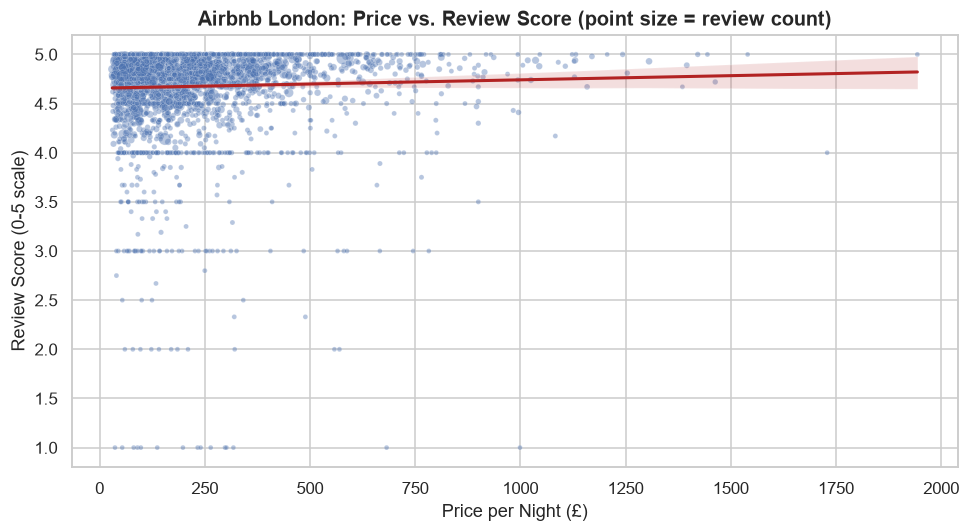

Correlation matrix (full dataset, not the plotting sample):
                      price  review_scores_rating  number_of_reviews
price                 1.000                 0.054             -0.094
review_scores_rating  0.054                 1.000              0.096
number_of_reviews    -0.094                 0.096              1.000


In [12]:
scatter_sample = airbnb.dropna(subset=["price", "review_scores_rating", "number_of_reviews"]).sample(
    n=min(3000, len(airbnb)), random_state=42
)

fig, ax = plt.subplots()
sns.scatterplot(
    data=scatter_sample, x="price", y="review_scores_rating",
    size="number_of_reviews", sizes=(10, 200), alpha=0.4, legend=False, ax=ax
)
sns.regplot(data=scatter_sample, x="price", y="review_scores_rating",
            scatter=False, ax=ax, color="firebrick", line_kws={"linewidth": 2})
ax.set_title("Airbnb London: Price vs. Review Score (point size = review count)")
ax.set_xlabel("Price per Night (£)")
ax.set_ylabel("Review Score (0-5 scale)")
plt.tight_layout()
plt.show()

full_corr = airbnb[["price", "review_scores_rating", "number_of_reviews"]].corr()
print("Correlation matrix (full dataset, not the plotting sample):")
print(full_corr.round(3))

## 7. Host Concentration — Single-Listing vs. Multi-Listing Hosts

**Business question:** Is London's Airbnb market dominated by
individual hosts renting one property, or by commercial/multi-property
operators? This is directly relevant to the ethics/regulation
discussion — cities regulate short-term rentals partly because
multi-listing "professional" hosts behave more like unlicensed hotel
operators than casual home-sharers.

**Chart chosen: Bar chart of host-count buckets**
The business question here is categorical ("how many hosts fall into
each ownership-scale bucket"), which is exactly what a bar chart is
built for — one bar per bucket, height = count.

**Why not a pie chart:** pie charts are difficult to compare precisely
when there are more than 3-4 categories or when slice sizes are close —
a bar chart lets the reader compare bucket heights accurately, which
matters since the smallest and largest buckets are the interesting ones.

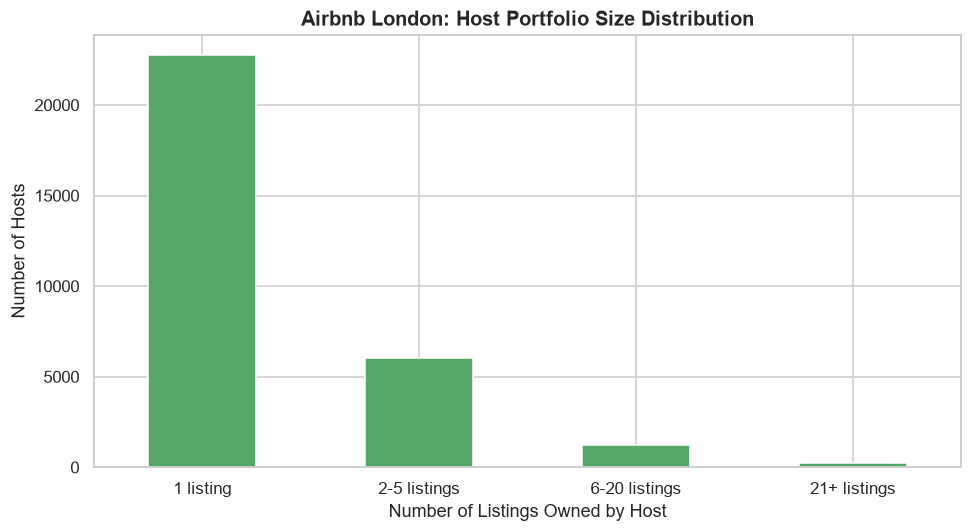

24.8% of hosts operate more than one listing.


In [13]:
host_listing_counts = airbnb.groupby("host_id")["id"].count()

def bucket_host(n):
    if n == 1:
        return "1 listing"
    elif n <= 5:
        return "2-5 listings"
    elif n <= 20:
        return "6-20 listings"
    else:
        return "21+ listings"

host_buckets = host_listing_counts.apply(bucket_host).value_counts()
bucket_order = ["1 listing", "2-5 listings", "6-20 listings", "21+ listings"]
host_buckets = host_buckets.reindex(bucket_order)

fig, ax = plt.subplots()
host_buckets.plot(kind="bar", ax=ax, color=sns.color_palette("deep")[2])
ax.set_title("Airbnb London: Host Portfolio Size Distribution")
ax.set_xlabel("Number of Listings Owned by Host")
ax.set_ylabel("Number of Hosts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

pct_multi = (host_listing_counts > 1).mean() * 100
print(f"{pct_multi:.1f}% of hosts operate more than one listing.")

## 8. Trip Type Breakdown — Booking.com

**Business question:** Is Booking.com London primarily serving business
or leisure travelers, and does that split affect review scores? This
matters for a hotel's marketing/positioning decision and helps explain
*why* review patterns look the way they do (business travelers often
rate differently than leisure travelers).

**Chart chosen: Grouped bar chart (trip_type x average review score)**
This directly compares average satisfaction across the two trip
segments — a grouped bar chart is the standard, most readable way to
compare one metric (avg score) across a small number of categories
(2 trip types).

**Why not a stacked bar chart:** stacking would be appropriate if we
were showing *composition* of a whole (e.g. % of reviews per trip type
stacked to 100%) — here we're comparing an average *value* across
groups, which grouped/side-by-side bars represent more accurately
without implying a part-to-whole relationship that doesn't exist.

C:\Users\Shivam Aher\AppData\Local\Temp\ipykernel_23308\1096877344.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=trip_summary, x="trip_type", y="avg_score", ax=ax, palette="deep")


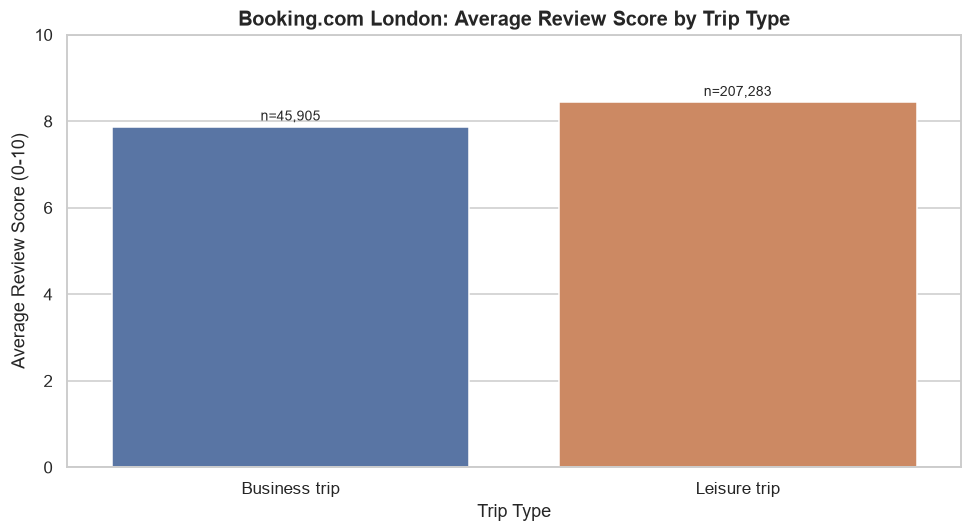

In [14]:
trip_summary = booking.dropna(subset=["trip_type"]).groupby("trip_type").agg(
    avg_score=("Reviewer_Score", "mean"),
    review_count=("Reviewer_Score", "count")
).reset_index()

fig, ax = plt.subplots()
sns.barplot(data=trip_summary, x="trip_type", y="avg_score", ax=ax, palette="deep")
ax.set_title("Booking.com London: Average Review Score by Trip Type")
ax.set_xlabel("Trip Type")
ax.set_ylabel("Average Review Score (0-10)")
ax.set_ylim(0, 10)
for i, row in trip_summary.iterrows():
    ax.text(i, row["avg_score"] + 0.15, f"n={row['review_count']:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## 9. Reviewer Nationality — Top 10 by Volume (Booking.com)

**Business question:** Which guest nationalities generate the most
reviews, and is there any indication of scoring variation by
nationality? This directly feeds the project's fairness/bias
discussion — a meaningful gap here is worth flagging as a potential
reviewer-bias pattern, not proof of it on its own.

**Chart chosen: Horizontal bar chart, top 10 nationalities by review
volume, colored/annotated with average score**
Horizontal bars again handle the long text labels (country names)
cleanly, and sorting by volume answers "who reviews the most" while the
annotation answers "do they rate differently" in the same chart —
avoiding a second redundant chart for a closely related question.

**Why not a full breakdown of all nationalities:** the dataset has
reviewers from 100+ countries; a full chart would be unreadable. Top 10
by volume captures the vast majority of the data's actual signal.

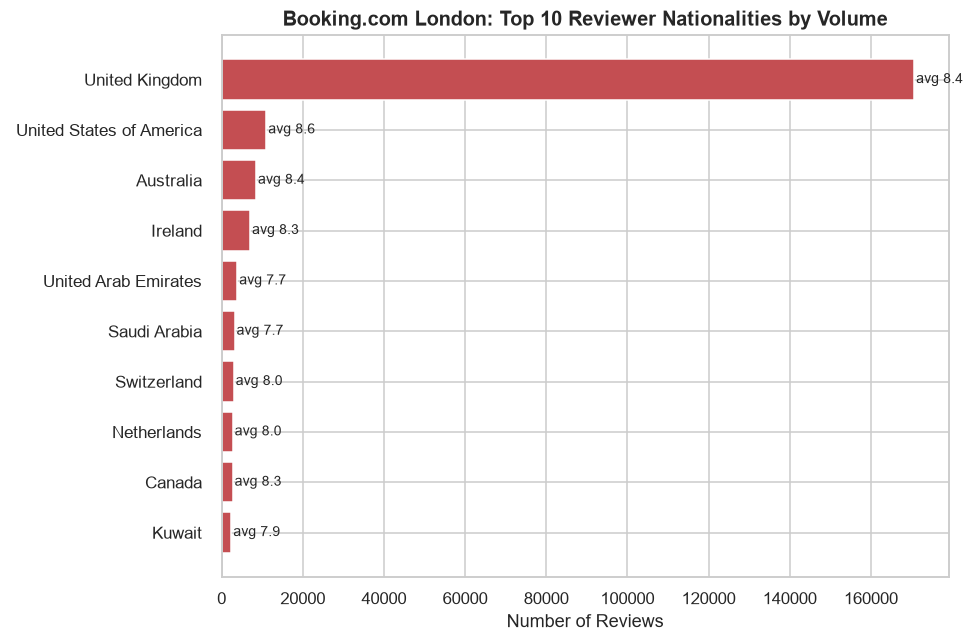

In [15]:
nat_summary = (
    booking.groupby("Reviewer_Nationality")
    .agg(review_count=("Reviewer_Score", "count"), avg_score=("Reviewer_Score", "mean"))
    .sort_values("review_count", ascending=False)
    .head(10)
    .sort_values("review_count")
)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(nat_summary.index, nat_summary["review_count"], color=sns.color_palette("deep")[3])
ax.set_title("Booking.com London: Top 10 Reviewer Nationalities by Volume")
ax.set_xlabel("Number of Reviews")
for bar, score in zip(bars, nat_summary["avg_score"]):
    ax.text(bar.get_width() + 500, bar.get_y() + bar.get_height() / 2,
            f"avg {score:.1f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 10. Guest-Perceived Value by Host Portfolio Segment

**Business question:** Does guest-perceived value differ across listings run by hosts with different portfolio sizes, and which groups may warrant a closer review of listing accuracy, amenities, and price/value messaging? This motivates the next ML task: estimate `review_scores_value` from listing characteristics that do not include review outcomes.

**Chart chosen: Boxplot with mean markers (0–5 scale)**
The boxplot shows the distribution and median of value scores in each host segment, while a diamond marks the mean that the planned regression model will estimate. The sample size is shown for each group so a difference is interpreted in light of how much evidence supports it. The full 0–5 scale is retained to avoid visually exaggerating small score gaps.

**Why not a bar chart of means alone:** it would hide the spread and ceiling clustering of ratings. The observed gap can guide an operational audit, but it does not establish that portfolio size causes ratings to differ.

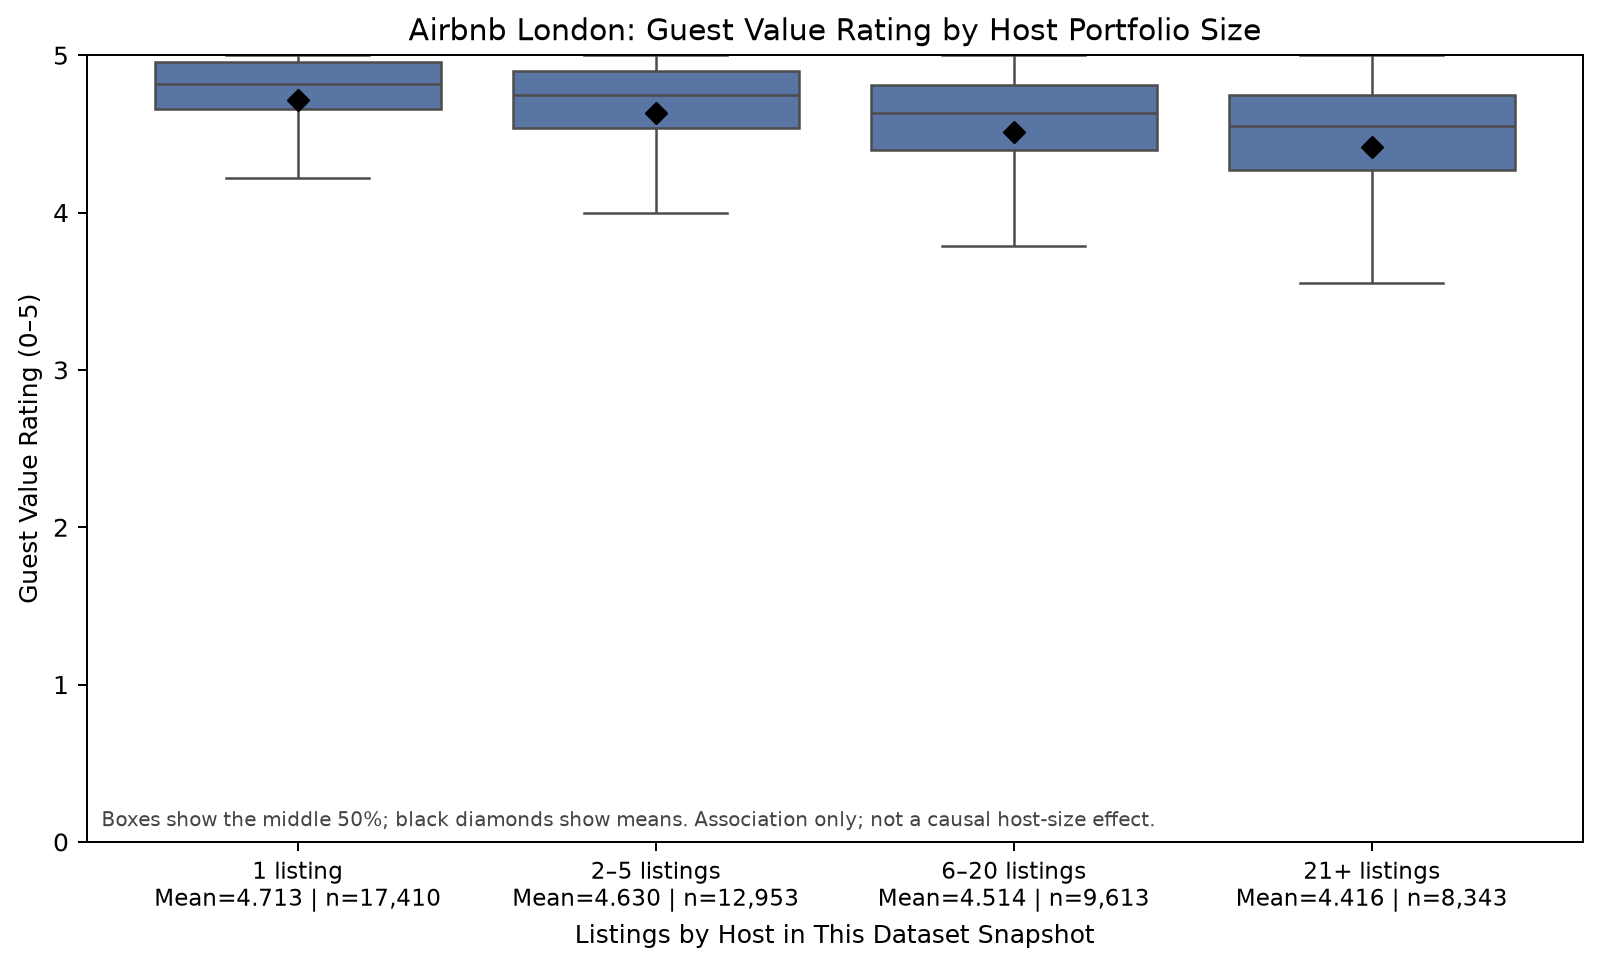

                        count   mean  median
host_portfolio_segment                      
1 listing               17410  4.713    4.82
2–5 listings            12953  4.630    4.75
6–20 listings            9613  4.514    4.63
21+ listings              8343  4.416    4.55


In [17]:
# Derive a chart-only host segment from the listing counts; do not expose host IDs.
value_df = airbnb[["id", "host_id", "review_scores_value"]].copy()
value_df["host_listing_count"] = value_df.groupby("host_id")["id"].transform("count")
value_df["host_portfolio_segment"] = pd.cut(
    value_df["host_listing_count"],
    bins=[0, 1, 5, 20, np.inf],
    labels=["1 listing", "2–5 listings", "6–20 listings", "21+ listings"],
    right=True,
)
value_df = value_df.dropna(subset=["review_scores_value", "host_portfolio_segment"])
segment_order = ["1 listing", "2–5 listings", "6–20 listings", "21+ listings"]
value_summary = value_df.groupby("host_portfolio_segment", observed=False)["review_scores_value"].agg(["count", "mean", "median"]).reindex(segment_order)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(
    data=value_df, x="host_portfolio_segment", y="review_scores_value",
    order=segment_order, showfliers=False, color=sns.color_palette("deep")[0], ax=ax
)
tick_labels = []
for x, segment in enumerate(segment_order):
    mean_score = value_summary.loc[segment, "mean"]
    count = int(value_summary.loc[segment, "count"])
    ax.scatter(x, mean_score, marker="D", color="black", s=34, zorder=4)
    tick_labels.append(f"{segment}\nMean={mean_score:.3f} | n={count:,}")
ax.set_xticks(range(len(segment_order)), tick_labels)
ax.tick_params(axis="x", labelsize=9)
ax.set_title("Airbnb London: Guest Value Rating by Host Portfolio Size")
ax.set_xlabel("Listings by Host in This Dataset Snapshot")
ax.set_ylabel("Guest Value Rating (0–5)")
ax.set_ylim(0, 5)
ax.text(0.01, 0.02, "Boxes show the middle 50%; black diamonds show means. Association only; not a causal host-size effect.", transform=ax.transAxes, fontsize=8, color="#444444")
plt.tight_layout()
plt.savefig("../reports/value_rating_by_host_segment.png", dpi=180, bbox_inches="tight")
plt.show()

print(value_summary.round(3).to_string())

## 11. Cross-Platform Summary Table

**Business question:** What's the single, decision-ready summary a
non-technical stakeholder (e.g. course faculty, or a hypothetical
business reader) would want, without reading every chart above?

**Format chosen: Summary table, not a chart**
Not every finding belongs in a chart. A compact table is the right
closing artifact here because the reader needs exact, precise, directly
comparable numbers across platforms — a chart would add visual noise
where precision is what's actually needed.

In [16]:
summary = comparison.groupby("platform").agg(
    n_records=("record_id", "count"),
    avg_price_gbp=("price_per_night_gbp", "mean"),
    avg_review_score=("review_score_0to10", "mean"),
    median_review_count=("review_count", "median"),
).round(2)

print(summary.to_string())

          n_records  avg_price_gbp  avg_review_score  median_review_count
platform                                                                 
airbnb        61617         241.07              9.34                  7.0
booking      262298            NaN              8.32                974.0


## Summary of EDA Findings

- Airbnb London listings average **higher** review scores than
  Booking.com London hotels (statistically significant, Welch's t-test).
- Price varies substantially by room type and borough on Airbnb — no
  price comparison possible on the Booking.com side (documented data gap).
- A meaningful share of Airbnb hosts operate multiple listings — relevant
  to the regulatory/ethics discussion on "professional" vs. casual hosts.
- Guest value ratings are lower on average across larger observed host portfolios in this snapshot: 4.713 for one-listing hosts versus 4.416 for 21+ listing hosts. This is an association, not evidence that portfolio size causes lower value ratings. The new distribution chart also shows group counts and score spread.
- Booking.com's guest base splits across business/leisure trip types with
  different average satisfaction levels.
- Reviewer nationality volume is concentrated in a handful of countries —
  worth deeper fairness analysis in the ethics section, not concluded here.

**Next stage:** build and evaluate a regression model for `review_scores_value` using listing characteristics. The goal is to learn whether available listing information predicts guest-perceived value well enough to guide further investigation, while checking errors across groups. The model will not establish causes or rank individual hosts.